In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU for now")

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


In [ ]:
!git clone https://github.com/IDKiro/DehazeFormer.git
%cd DehazeFormer
!ls

Cloning into 'DehazeFormer'...
remote: Enumerating objects: 94, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 94 (delta 17), reused 11 (delta 11), pack-reused 70 (from 2)
Receiving objects: 100% (94/94), 768.88 KiB | 14.24 MiB/s, done.
Resolving deltas: 100% (43/43), done.
/content/DehazeFormer/DehazeFormer
configs   figs	   models     requirements.txt	test.py   utils
datasets  LICENSE  README.md  run.sh		train.py


In [ ]:
%cd /content/DehazeFormer

!pip install timm pytorch-msssim

/content/DehazeFormer


In [ ]:
import os
import shutil

checkpoint = "/content/dehazeformer-t.pth"
destination = "/content/DehazeFormer/dehazeformer-t.pth"

if os.path.exists(checkpoint):
    shutil.move(checkpoint, destination)
    print("SUCCESS: Checkpoint is ready!")
    print("File size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")
elif os.path.exists(destination):
    print("SUCCESS: Checkpoint is already in the project folder!")
    print("File size:", round(os.path.getsize(destination) / (1024 * 1024), 2), "MB")
else:
    print("Checkpoint not found. Files in /content:")
    print(os.listdir("/content"))

SUCCESS: Checkpoint is already in the project folder!
File size: 2.9 MB


In [ ]:
%cd /content/DehazeFormer

!sed -n '1,240p' test.py

/content/DehazeFormer
import os
import argparse
import torch
import torch.nn as nn
import torch.nn.functional as F
from pytorch_msssim import ssim
from torch.utils.data import DataLoader
from collections import OrderedDict

from utils import AverageMeter, write_img, chw_to_hwc
from datasets.loader import PairLoader
from models import *


parser = argparse.ArgumentParser()
parser.add_argument('--model', default='dehazeformer-s', type=str, help='model name')
parser.add_argument('--num_workers', default=16, type=int, help='number of workers')
parser.add_argument('--data_dir', default='./data/', type=str, help='path to dataset')
parser.add_argument('--save_dir', default='./saved_models/', type=str, help='path to models saving')
parser.add_argument('--result_dir', default='./results/', type=str, help='path to results saving')
parser.add_argument('--dataset', default='RESIDE-IN', type=str, help='dataset name')
parser.add_argument('--exp', default='indoor', type=str, help='experiment setting'

In [ ]:
import torch

path = "/content/DehazeFormer/dehazeformer-t.pth"
checkpoint = torch.load(path, map_location="cpu", weights_only=False)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", list(checkpoint.keys())[:20])
    if "state_dict" in checkpoint:
        print("State dict keys:", list(checkpoint["state_dict"].keys())[:5])
    else:
        print("This checkpoint does not contain a 'state_dict' key.")

Checkpoint type: <class 'dict'>
Checkpoint keys: ['state_dict']
State dict keys: ['module.patch_embed.proj.weight', 'module.patch_embed.proj.bias', 'module.layer1.blocks.0.attn.conv.weight', 'module.layer1.blocks.0.attn.conv.bias', 'module.layer1.blocks.0.attn.V.weight']


In [ ]:
%cd /content/DehazeFormer

import torch
from collections import OrderedDict
from models import dehazeformer_t

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create the architecture that matches dehazeformer-t.pth
model = dehazeformer_t().to(device)

# Load pretrained weights
checkpoint = torch.load(
    "/content/DehazeFormer/dehazeformer-t.pth",
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["state_dict"]

# Remove the DataParallel "module." prefix
new_state_dict = OrderedDict(
    (key[7:] if key.startswith("module.") else key, value)
    for key, value in state_dict.items()
)

model.load_state_dict(new_state_dict)
model.eval()

print("Model loaded successfully!")
print("Device:", device)

/content/DehazeFormer
Model loaded successfully!
Device: cuda


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Screenshot 2026-10-28 151622.png to Screenshot 2026-10-28 151622.png


In [1]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Get uploaded image filename
filename = next(iter(uploaded.keys()))
img = Image.open(filename).convert("RGB")

# Convert image to tensor in the range [-1, 1]
img_array = np.array(img).astype(np.float32) / 255.0
input_tensor = torch.from_numpy(img_array).permute(2, 0, 1).unsqueeze(0)
input_tensor = input_tensor * 2.0 - 1.0
input_tensor = input_tensor.to(device)

# Run pretrained model
with torch.no_grad():
    output = model(input_tensor).clamp(-1, 1)

# Convert output back to an image
output = (output * 0.5 + 0.5).clamp(0, 1)
output_array = output.squeeze(0).permute(1, 2, 0).cpu().numpy()
output_array = (output_array * 255).astype(np.uint8)

# Save restored image
output_path = "/content/dehazed_output.png"
Image.fromarray(output_array).save(output_path)

# Display comparison
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title("Original Hazy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_array)
plt.title("Dehazed Output")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Saved dehazed image to:", output_path)

NameError: name 'uploaded' is not defined

In [2]:

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:

import os

base = "/content/drive/MyDrive"

print("Folders and files in Google Drive:")
for item in os.listdir(base):
    print(item)


Folders and files in Google Drive:
Colab Notebooks
Untitled document (1).gdoc
Untitled document.gdoc
Resume.gdoc
34dd-9d6a-4744-9216-950c7a0154fc (1).mp3
Dehazing_Project


In [4]:

import os

dataset_path = "/content/drive/MyDrive/Dehazing_Project"

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    for name in files[:5]:
        print(f"{indent}  {name}")
    if level >= 3:
        dirs[:] = []


Dehazing_Project/
  rise/
    metadata_indoor.csv
    outdoor/
      hazy/
        0320_1_0.16.jpg
        0320_0.9_0.08.jpg
        0311_0.8_0.16.jpg
        0308_1_0.16.jpg
        0316_0.85_0.12.jpg
      clear/
    indoor/
      hazy/
      clear/
        1400.png
        1401.png
        1402.png
        1403.png
        1404.png


In [5]:

import os

dataset_path = "/content/drive/MyDrive/Dehazing_Project/rise"

for scene in ["indoor", "outdoor"]:
    print(f"\n--- {scene.upper()} ---")

    for category in ["hazy", "clear"]:
        folder = os.path.join(dataset_path, scene, category)

        if os.path.isdir(folder):
            images = [
                f for f in os.listdir(folder)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ]
            print(f"{category}: {len(images)} images")
            print("Examples:", images[:5])
        else:
            print(f"Missing folder: {folder}")



--- INDOOR ---
hazy: 0 images
Examples: []
clear: 50 images
Examples: ['1400.png', '1401.png', '1402.png', '1403.png', '1404.png']

--- OUTDOOR ---
hazy: 409 images
Examples: ['0320_1_0.16.jpg', '0320_0.9_0.08.jpg', '0311_0.8_0.16.jpg', '0308_1_0.16.jpg', '0316_0.85_0.12.jpg']
clear: 0 images
Examples: []


In [6]:

import os

dataset_path = "/content/drive/MyDrive/Dehazing_Project/rise"
image_exts = (".jpg", ".jpeg", ".png", ".bmp")

for root, dirs, files in os.walk(dataset_path):
    images = [f for f in files if f.lower().endswith(image_exts)]

    if images:
        print(f"\nFolder: {root}")
        print(f"Image count: {len(images)}")
        print("First 8 images:", images[:8])



Folder: /content/drive/MyDrive/Dehazing_Project/rise/outdoor/hazy
Image count: 444
First 8 images: ['0320_1_0.16.jpg', '0320_0.9_0.08.jpg', '0311_0.8_0.16.jpg', '0308_1_0.16.jpg', '0316_0.85_0.12.jpg', '0309_1_0.08.jpg', '0306_0.8_0.16.jpg', '0319_0.9_0.16.jpg']

Folder: /content/drive/MyDrive/Dehazing_Project/rise/indoor/clear
Image count: 50
First 8 images: ['1400.png', '1401.png', '1402.png', '1403.png', '1404.png', '1405.png', '1406.png', '1407.png']


In [7]:

import os
import pandas as pd

csv_path = "/content/drive/MyDrive/Dehazing_Project/rise/metadata_indoor.csv"

df = pd.read_csv(csv_path)

print("Metadata shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 10 rows:")
display(df.head(10))


Metadata shape: (50, 3)

Column names:
['image_id', 'clear_image_path', 'hazy_image_paths']

First 10 rows:


,image_id,clear_image_path,hazy_image_paths
0,1400,clear/1400.png,"['hazy/1400_1.png', 'hazy/1400_2.png', 'hazy/1..."
1,1401,clear/1401.png,"['hazy/1401_1.png', 'hazy/1401_2.png', 'hazy/1..."
2,1402,clear/1402.png,"['hazy/1402_1.png', 'hazy/1402_2.png', 'hazy/1..."
3,1403,clear/1403.png,"['hazy/1403_1.png', 'hazy/1403_2.png', 'hazy/1..."
4,1404,clear/1404.png,"['hazy/1404_1.png', 'hazy/1404_2.png', 'hazy/1..."
5,1405,clear/1405.png,"['hazy/1405_1.png', 'hazy/1405_2.png', 'hazy/1..."
6,1406,clear/1406.png,"['hazy/1406_1.png', 'hazy/1406_2.png', 'hazy/1..."
7,1407,clear/1407.png,"['hazy/1407_1.png', 'hazy/1407_2.png', 'hazy/1..."
8,1408,clear/1408.png,"['hazy/1408_1.png', 'hazy/1408_2.png', 'hazy/1..."
9,1409,clear/1409.png,"['hazy/1409_1.png', 'hazy/1409_2.png', 'hazy/1..."


In [8]:

import os

base = "/content/drive/MyDrive/Dehazing_Project"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)

    if level <= 3:
        print(root, "| folders:", dirs, "| image files:",
              sum(f.lower().endswith((".jpg", ".jpeg", ".png"))
                  for f in files))


/content/drive/MyDrive/Dehazing_Project | folders: ['rise'] | image files: 0
/content/drive/MyDrive/Dehazing_Project/rise | folders: ['outdoor', 'indoor'] | image files: 0
/content/drive/MyDrive/Dehazing_Project/rise/outdoor | folders: ['hazy', 'clear'] | image files: 0
/content/drive/MyDrive/Dehazing_Project/rise/outdoor/hazy | folders: [] | image files: 500
/content/drive/MyDrive/Dehazing_Project/rise/outdoor/clear | folders: [] | image files: 0
/content/drive/MyDrive/Dehazing_Project/rise/indoor | folders: ['hazy', 'clear'] | image files: 0
/content/drive/MyDrive/Dehazing_Project/rise/indoor/hazy | folders: [] | image files: 23
/content/drive/MyDrive/Dehazing_Project/rise/indoor/clear | folders: [] | image files: 50


In [9]:

import os
import ast
import pandas as pd

base = "/content/drive/MyDrive/Dehazing_Project/rise/indoor"
csv_path = os.path.join(base, "..", "metadata_indoor.csv")

df = pd.read_csv(csv_path)

valid_pairs = []
missing_hazy = 0
missing_clear = 0

for _, row in df.iterrows():
    clear_path = os.path.join(base, row["clear_image_path"])

    if not os.path.isfile(clear_path):
        missing_clear += 1
        continue

    hazy_paths = ast.literal_eval(row["hazy_image_paths"])

    for hazy_rel_path in hazy_paths:
        hazy_path = os.path.join(base, hazy_rel_path)

        if os.path.isfile(hazy_path):
            valid_pairs.append((hazy_path, clear_path))
        else:
            missing_hazy += 1

print("Metadata rows:", len(df))
print("Valid hazy-clear pairs:", len(valid_pairs))
print("Missing clear references:", missing_clear)
print("Missing hazy images listed in metadata:", missing_hazy)

print("\nExample valid pairs:")
for hazy, clear in valid_pairs[:5]:
    print("Hazy:", os.path.basename(hazy))
    print("Clear:", os.path.basename(clear))
    print()


Metadata rows: 50
Valid hazy-clear pairs: 90
Missing clear references: 0
Missing hazy images listed in metadata: 410

Example valid pairs:
Hazy: 1400_1.png
Clear: 1400.png

Hazy: 1400_2.png
Clear: 1400.png

Hazy: 1400_3.png
Clear: 1400.png

Hazy: 1400_4.png
Clear: 1400.png

Hazy: 1400_5.png
Clear: 1400.png



In [13]:

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [16]:

%cd /content
!git clone https://github.com/IDKiro/DehazeFormer.git



/content
Cloning into 'DehazeFormer'...
remote: Enumerating objects: 94, done.
remote: Counting objects: 100% (24/24), done.
remote: Compressing objects: 100% (13/13), done.
remote: Total 94 (delta 17), reused 11 (delta 11), pack-reused 70 (from 2)
Receiving objects: 100% (94/94), 768.88 KiB | 3.88 MiB/s, done.
Resolving deltas: 100% (43/43), done.


In [17]:

!pip install timm pytorch-msssim scikit-image


In [18]:

import os

print("Checkpoint exists:",
      os.path.exists("/content/DehazeFormer/dehazeformer-t.pth"))


Checkpoint exists: False


In [19]:

from google.colab import files

uploaded = files.upload()


Saving dehazeformer-t.pth to dehazeformer-t.pth


In [21]:

import os

for folder in ["/content", "/content/drive/MyDrive/Dehazing_Project"]:
    print(f"\nSearching: {folder}")
    for root, dirs, files in os.walk(folder):
        if "dehazeformer-t.pth" in files:
            print("FOUND:", os.path.join(root, "dehazeformer-t.pth"))



Searching: /content
FOUND: /content/dehazeformer-t.pth

Searching: /content/drive/MyDrive/Dehazing_Project


In [22]:

import shutil
import os

source = "/content/dehazeformer-t.pth"
destination = "/content/DehazeFormer/dehazeformer-t.pth"

shutil.move(source, destination)

print("Checkpoint ready:", os.path.exists(destination))


Checkpoint ready: True


In [24]:

%cd /content/DehazeFormer

import torch
from collections import OrderedDict
from models import dehazeformer_t

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = dehazeformer_t().to(device)

checkpoint = torch.load(
    "dehazeformer-t.pth",
    map_location="cpu",
    weights_only=False
)

state_dict = checkpoint["state_dict"]
state_dict = OrderedDict(
    (k[7:] if k.startswith("module.") else k, v)
    for k, v in state_dict.items()
)

model.load_state_dict(state_dict)
model.eval()

print("Model loaded successfully!")
print("Device:", device)


/content/DehazeFormer
Model loaded successfully!
Device: cuda


In [25]:

import os
import ast
import time
import numpy as np
import pandas as pd
import torch
from PIL import Image
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

base = "/content/drive/MyDrive/Dehazing_Project/rise/indoor"
csv_path = os.path.join(base, "..", "metadata_indoor.csv")
df = pd.read_csv(csv_path)

valid_pairs = []
for _, row in df.iterrows():
    clear_path = os.path.join(base, row["clear_image_path"])
    if not os.path.isfile(clear_path):
        continue
    for rel_path in ast.literal_eval(row["hazy_image_paths"]):
        hazy_path = os.path.join(base, rel_path)
        if os.path.isfile(hazy_path):
            valid_pairs.append((hazy_path, clear_path))

print("Valid pairs:", len(valid_pairs))

def load_image(path):
    img = Image.open(path).convert("RGB")
    arr = np.asarray(img, dtype=np.float32) / 255.0
    tensor = torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)
    return img, (tensor * 2.0 - 1.0).to(device)

results = []
os.makedirs("/content/dehazed_results", exist_ok=True)

for i, (hazy_path, clear_path) in enumerate(valid_pairs):
    hazy_img, input_tensor = load_image(hazy_path)
    clear_img = Image.open(clear_path).convert("RGB")

    if clear_img.size != hazy_img.size:
        clear_img = clear_img.resize(hazy_img.size, Image.Resampling.BICUBIC)

    clear_array = np.asarray(clear_img, dtype=np.float32) / 255.0
    hazy_array = np.asarray(hazy_img, dtype=np.float32) / 255.0

    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()

    with torch.no_grad():
        output = model(input_tensor).clamp(-1, 1)

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    output_array = (
        output.squeeze(0).permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5
    ).clip(0, 1)

    results.append({
        "hazy_image": os.path.basename(hazy_path),
        "clear_image": os.path.basename(clear_path),
        "PSNR_before": peak_signal_noise_ratio(
            clear_array, hazy_array, data_range=1.0
        ),
        "PSNR_after": peak_signal_noise_ratio(
            clear_array, output_array, data_range=1.0
        ),
        "SSIM_before": structural_similarity(
            clear_array, hazy_array, channel_axis=2, data_range=1.0
        ),
        "SSIM_after": structural_similarity(
            clear_array, output_array, channel_axis=2, data_range=1.0
        ),
        "inference_seconds": elapsed
    })

    if i == 0:
        Image.fromarray(
            (output_array * 255).astype(np.uint8)
        ).save("/content/dehazed_results/example_dehazed.png")

    if (i + 1) % 10 == 0:
        print(f"Processed {i + 1}/{len(valid_pairs)}")

results_df = pd.DataFrame(results)
results_df.to_csv("/content/dehazing_evaluation.csv", index=False)

print("\n===== EVALUATION SUMMARY =====")
print("Pairs evaluated:", len(results_df))
print(f"PSNR before: {results_df['PSNR_before'].mean():.3f} dB")
print(f"PSNR after:  {results_df['PSNR_after'].mean():.3f} dB")
print(f"SSIM before: {results_df['SSIM_before'].mean():.4f}")
print(f"SSIM after:  {results_df['SSIM_after'].mean():.4f}")
print(f"Average inference time: {results_df['inference_seconds'].mean():.4f} sec/image")
print("\nCSV saved to /content/dehazing_evaluation.csv")


Valid pairs: 500
Processed 10/500
Processed 20/500
Processed 30/500
Processed 40/500
Processed 50/500
Processed 60/500
Processed 70/500
Processed 80/500
Processed 90/500
Processed 100/500
Processed 110/500
Processed 120/500
Processed 130/500
Processed 140/500
Processed 150/500
Processed 160/500
Processed 170/500
Processed 180/500
Processed 190/500
Processed 200/500
Processed 210/500
Processed 220/500
Processed 230/500
Processed 240/500
Processed 250/500
Processed 260/500
Processed 270/500
Processed 280/500
Processed 290/500
Processed 300/500
Processed 310/500
Processed 320/500
Processed 330/500
Processed 340/500
Processed 350/500
Processed 360/500
Processed 370/500
Processed 380/500
Processed 390/500
Processed 400/500
Processed 410/500
Processed 420/500
Processed 430/500
Processed 440/500
Processed 450/500
Processed 460/500
Processed 470/500
Processed 480/500
Processed 490/500
Processed 500/500

===== EVALUATION SUMMARY =====
Pairs evaluated: 500
PSNR before: 11.975 dB
PSNR after:  23.

In [26]:

import os
import pandas as pd

csv_path = "/content/dehazing_evaluation.csv"

if os.path.exists(csv_path):
    results_df = pd.read_csv(csv_path)

    print("Rows in CSV:", len(results_df))
    print("Unique hazy filenames:", results_df["hazy_image"].nunique())
    print("\nFirst 10 evaluated pairs:")
    print(results_df[["hazy_image", "clear_image"]].head(10).to_string(index=False))

    print("\nMetric averages:")
    print(results_df[[
        "PSNR_before", "PSNR_after",
        "SSIM_before", "SSIM_after",
        "inference_seconds"
    ]].mean())
else:
    print("CSV not found. Run the evaluation cell again.")


Rows in CSV: 500
Unique hazy filenames: 500

First 10 evaluated pairs:
 hazy_image clear_image
 1400_1.png    1400.png
 1400_2.png    1400.png
 1400_3.png    1400.png
 1400_4.png    1400.png
 1400_5.png    1400.png
 1400_6.png    1400.png
 1400_7.png    1400.png
 1400_8.png    1400.png
 1400_9.png    1400.png
1400_10.png    1400.png

Metric averages:
PSNR_before          11.974826
PSNR_after           23.143056
SSIM_before           0.693425
SSIM_after            0.920358
inference_seconds     0.105285
dtype: float64


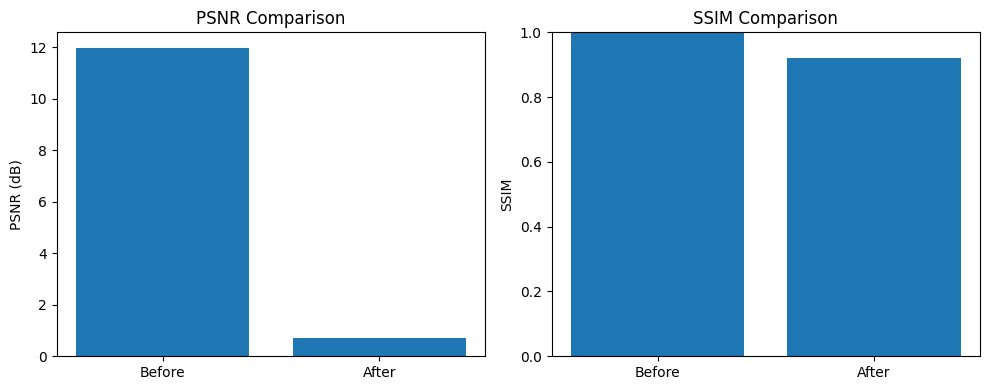

Graph saved to /content/dehazing_metrics.png


In [27]:

import matplotlib.pyplot as plt
import numpy as np

metrics = ["PSNR", "SSIM"]
before = [
    results_df["PSNR_before"].mean(),
    results_df["SSIM_before"].mean()
]
after = [
    results_df["PSNR_after"].mean(),
    results_df["SSIM_after"].mean()
]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].bar(["Before", "After"], before)
axes[0].set_title("PSNR Comparison")
axes[0].set_ylabel("PSNR (dB)")

axes[1].bar(["Before", "After"], after)
axes[1].set_title("SSIM Comparison")
axes[1].set_ylabel("SSIM")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig("/content/dehazing_metrics.png", dpi=200, bbox_inches="tight")
plt.show()

print("Graph saved to /content/dehazing_metrics.png")


In [29]:

from google.colab import files

files.download("/content/dehazing_evaluation.csv")
files.download("/content/dehazing_metrics.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

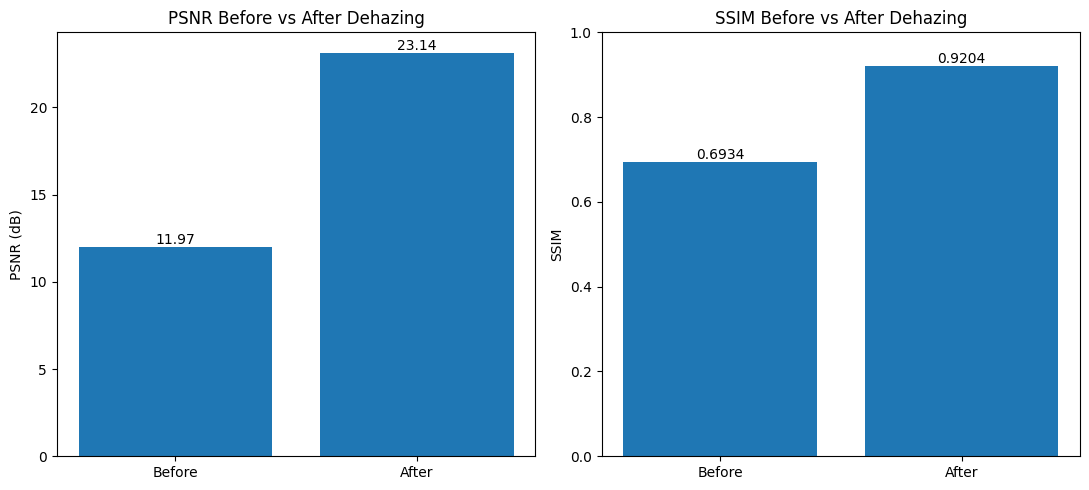

Graph created: True
Saved at: /content/dehazing_metrics.png


In [30]:

import pandas as pd
import matplotlib.pyplot as plt
import os

# Load your evaluation results
results_df = pd.read_csv("/content/dehazing_evaluation.csv")

# Calculate averages
psnr_before = results_df["PSNR_before"].mean()
psnr_after = results_df["PSNR_after"].mean()
ssim_before = results_df["SSIM_before"].mean()
ssim_after = results_df["SSIM_after"].mean()

# Create two comparison graphs
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

axes[0].bar(["Before", "After"], [psnr_before, psnr_after])
axes[0].set_title("PSNR Before vs After Dehazing")
axes[0].set_ylabel("PSNR (dB)")
axes[0].bar_label(axes[0].containers[0], fmt="%.2f")

axes[1].bar(["Before", "After"], [ssim_before, ssim_after])
axes[1].set_title("SSIM Before vs After Dehazing")
axes[1].set_ylabel("SSIM")
axes[1].set_ylim(0, 1)
axes[1].bar_label(axes[1].containers[0], fmt="%.4f")

plt.tight_layout()

graph_path = "/content/dehazing_metrics.png"
plt.savefig(graph_path, dpi=200, bbox_inches="tight")
plt.show()

print("Graph created:", os.path.exists(graph_path))
print("Saved at:", graph_path)


In [31]:

from google.colab import files
files.download("/content/dehazing_metrics.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>